# Monitoring event-volume shifts

Detect unusual volumes in a synthetic operational event series and measure false alerts.

Estimate the normal volume and spread using an initial calibration period. Freeze the threshold, then score a later interval with known shifts. Keep chronology intact so the injected events cannot influence the baseline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score,
    recall_score,
    average_precision_score,
    confusion_matrix,
)

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

TP 5 FP 0 FN 0 TN 95
precision / recall / average precision [1. 1. 1.]


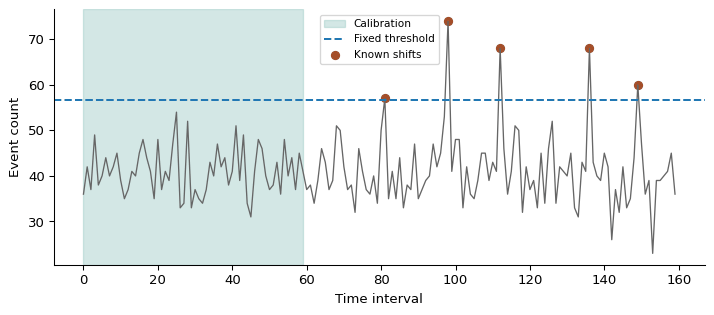

In [2]:
rng = np.random.default_rng(83)
series = rng.poisson(40, 160)
known = np.zeros(160, bool)
known[[81, 98, 112, 136, 149]] = True
series[known] += [23, 34, 18, 32, 26]
base = series[:60]
scores = (series - base.mean()) / base.std(ddof=1)
active = scores[60:] > 3
truth = known[60:]
tn, fp, fn, tp = confusion_matrix(truth, active, labels=[False, True]).ravel()
print(f"TP {tp} FP {fp} FN {fn} TN {tn}")
print(
    "precision / recall / average precision",
    np.round(
        [
            precision_score(truth, active, zero_division=0),
            recall_score(truth, active),
            average_precision_score(truth, scores[60:]),
        ],
        3,
    ),
)
fig, ax = plt.subplots(figsize=(7.4, 3.2), constrained_layout=True)
ax.plot(series, color="0.4", lw=1)
ax.axvspan(0, 59, color="#83bdb6", alpha=0.35, label="Calibration")
ax.axhline(base.mean() + 3 * base.std(ddof=1), ls="--", label="Fixed threshold")
ix = np.flatnonzero(known)
ax.scatter(ix, series[ix], color="#a44e29", label="Known shifts")
ax.set(xlabel="Time interval", ylabel="Event count")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

Detection quality depends on the calibration period and the magnitude of each shift. The labels describe event volume, not an incident cause.

## Exercise

Double the baseline volume after the calibration period and measure the false-alert burden.

## References

[NIST SP 800-92, computer security log management](https://doi.org/10.6028/NIST.SP.800-92)

[OWASP, Logging Cheat Sheet](https://cheatsheetseries.owasp.org/cheatsheets/Logging_Cheat_Sheet.html)